# Assignment 2(due on 10/28)

## Student: 王玥（12632741），Github: Guanzhuag

## 批改人：张鹏

## 得分：88/100 

In [4]:
#1、Significant earthquakes since 2150 B.C
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

Sig_Eqs = pd.read_csv("/home/zhangp/桌面/A2/earthquakes-2026-10-30_17-09-02_+0800.tsv", sep="\t")  # 助教更改读取路径
Sig_Eqs.head()

,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
0,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1.0,-2150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2.0,-2000.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,3.0,-2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
4,NaN,5877.0,-1610.0,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN


In [5]:
#1、1
country=Sig_Eqs.groupby(['Country'])['Deaths'].sum().sort_values(ascending=False)
country.head(20)

Country
CHINA           2139225.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
HAITI            323484.0
AZERBAIJAN       319251.0
SYRIA            289826.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64

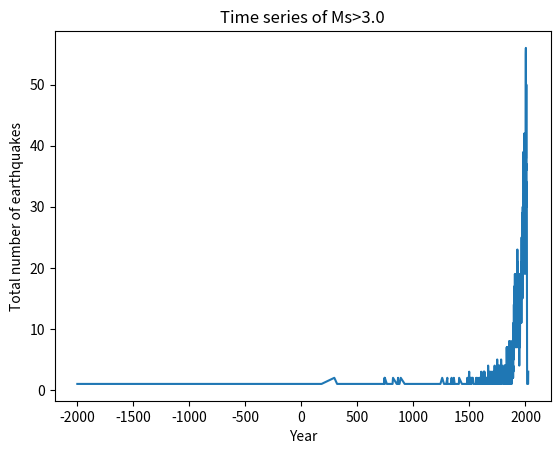

In [6]:
#1、2
total_number=Sig_Eqs.loc[Sig_Eqs['Ms']>3.0].groupby(['Year'])['Ms'].count().plot(kind='line')
plt.xlabel('Year')
plt.ylabel('Total number of earthquakes')
plt.title('Time series of Ms>3.0')
plt.show()

In [7]:
#1.3
def CountEq_LargestEq(country):
    data=Sig_Eqs.loc[Sig_Eqs['Country']==country]
    total_number=len(data)
    max=data.sort_values(by='Ms', ascending=False).head(1)
    year=max['Year'].iloc[0]
    location=max['Location Name'].iloc[0]
    return  total_number,year,location
CountEq_LargestEq('CHINA')


countries=Sig_Eqs['Country'].dropna().unique()
result=pd.DataFrame(columns=['Country', 'Total_number', 'Year', 'Location'])
for x in countries:
    total_number,year,location=CountEq_LargestEq(x)
    new=pd.DataFrame([{'Country': x,'Total_number':total_number,'Year':year,'Location':location}])
    result=pd.concat([result, new]).reset_index(drop=True).sort_values(by='Total_number', ascending=False)
result.head(10)


/tmp/ipykernel_1571487/2428103412.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result=pd.concat([result, new]).reset_index(drop=True).sort_values(by='Total_number', ascending=False)


,Country,Total_number,Year,Location
0,CHINA,627,1920.0,"CHINA: GANSU PROVINCE, SHANXI PROVINCE"
1,JAPAN,429,869.0,JAPAN: SANRIKU
2,INDONESIA,427,2004.0,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
3,IRAN,385,856.0,"IRAN: DAMGHAN, QUMIS"
4,TURKEY,359,1999.0,"TURKEY: ISTANBUL, KOCAELI, SAKARYA"
5,ITALY,338,1915.0,"ITALY: MARSICA, AVEZZANO, ABRUZZI"
6,GREECE,296,365.0,GREECE: CRETE: KNOSSOS
7,USA,283,1957.0,ALASKA
8,PHILIPPINES,233,1897.0,"PHILIPPINES: MINDANAO, ZAMBOANGA, SULU, ISABELA"
9,MEXICO,217,1787.0,"MEXICO: SAN MARCOS, OAXACA"


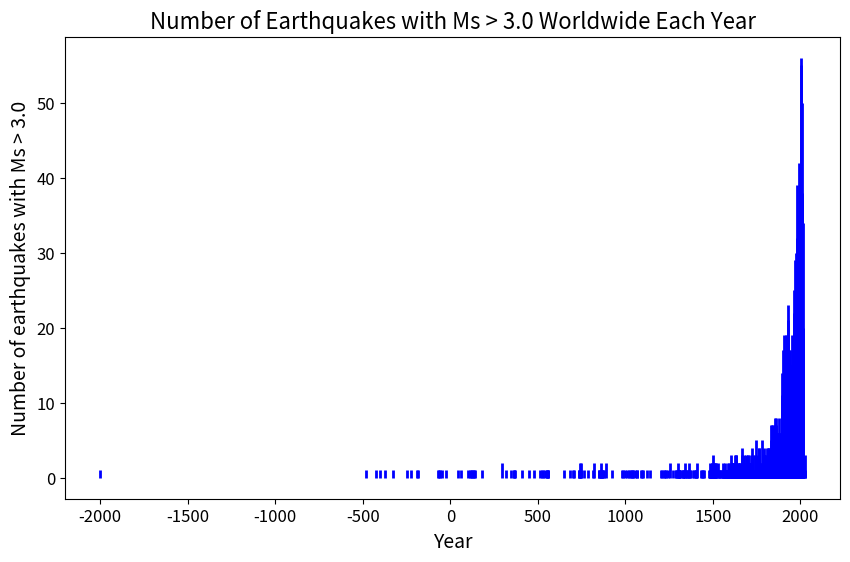

In [9]:
#1.2 助教添加
# 筛选出震级大于6.0的地震
large_quakes = Sig_Eqs[Sig_Eqs['Ms'] > 3.0]

# 按年份对数据进行分组，并得到每年的地震次数
quakes_by_year = large_quakes.groupby('Year')['Ms'].count()

plt.figure(figsize=(10, 6))
plt.vlines(quakes_by_year.index, ymin=0, ymax=quakes_by_year.values, color='blue', linewidth=2)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Number of earthquakes with Ms > 3.0', fontsize=14)
plt.title('Number of Earthquakes with Ms > 3.0 Worldwide Each Year', fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=12)

# Displaying the plot
plt.show()

### 第一题代码运行正常，可以输出正确结果，报告中也展示了输出内容，也针对问题给出文字分析。第二问绘图有一点点问题，没有数据的年份不应该有数据，建议绘制竖线图或者删除NAN值后绘图，见上面代码助教添加代码


### 得分：23/25
### --------------------------------------------------------------------------------------------

/tmp/ipykernel_1571487/4170148844.py:7: DtypeWarning: Columns (4,8,9,10,11,14,15,24,25,27,29,31,34,37,38,40,41,45,49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  temp=pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv")  # 助教更改读取路径


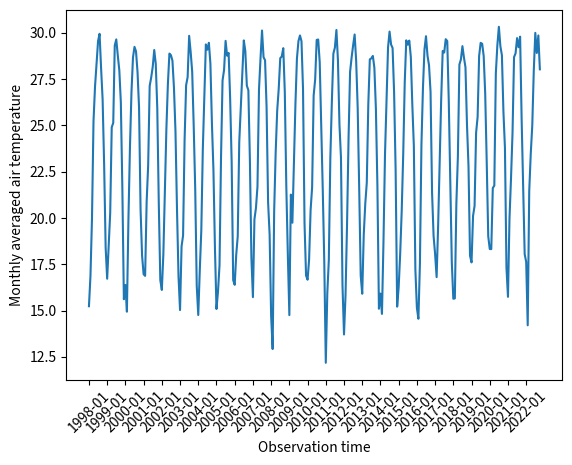

In [8]:
#2、Air temperature in Shenzhen 1998-2022

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

temp=pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv")  # 助教更改读取路径
temp['TMP'] =temp[temp['TMP']!=+9999]['TMP'].str[0:5].astype(float)/10
temp = temp[(temp['TMP']>=-93.2)&(temp['TMP']<= 61.8)]
temp['TMP']
temp['month']=temp['DATE'].str[0:7]
mtemp=temp.groupby('month')['TMP'].mean()

plt.plot(mtemp.index, mtemp.values)
plt.xlabel('Observation time')
plt.ylabel('Monthly averaged air temperature') 
plt.xticks(ticks=mtemp.index[::12],rotation=45) 
plt.show()

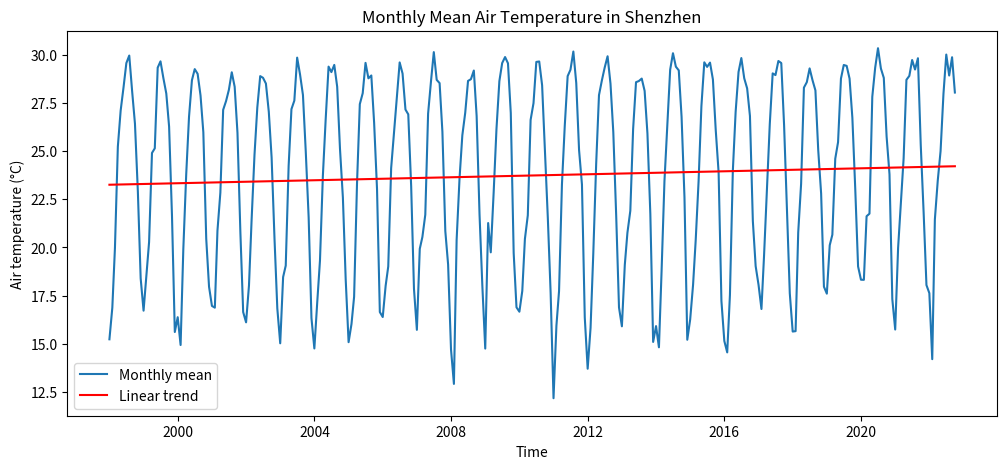

Slope: 0.03873600636339173 °C/year
P-value: 0.33910707287724584


In [10]:
#助教添加
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

weather = pd.read_csv("/home/zhangp/桌面/A2/Baoan_Weather_1998_2022.csv", low_memory=False)  # 助教更改读取路径

tmp = weather["TMP"].str.split(",", expand=True)
weather["time"] = pd.to_datetime(weather["DATE"])
weather["temperature"] = pd.to_numeric(tmp[0], errors="coerce") / 10
weather["quality"] = tmp[1]

weather = weather[
    (tmp[0] != "+9999")
    & weather["quality"].isin(["0", "1", "4", "5", "9"])
]

monthly_temperature = (
    weather.set_index("time")["temperature"]
    .resample("MS")
    .mean()
)

x = (monthly_temperature.index - monthly_temperature.index[0]).days / 365.25
temperature_trend = stats.linregress(x, monthly_temperature.values)

plt.figure(figsize=(12, 5))
plt.plot(monthly_temperature.index, monthly_temperature.values, label="Monthly mean")
plt.plot(
    monthly_temperature.index,
    temperature_trend.intercept + temperature_trend.slope * x,
    color="red",
    label="Linear trend"
)
plt.xlabel("Time")
plt.ylabel("Air temperature (°C)")
plt.title("Monthly Mean Air Temperature in Shenzhen")
plt.legend()
plt.show()

print("Slope:", temperature_trend.slope, "°C/year")
print("P-value:", temperature_trend.pvalue)

### 代码运行正确且有相应分析，但没有guide中的数据筛选，后续趋势分析建议采用拟合方法进行


### 得分：8/10
### --------------------------------------------------------------------------------------------

In [11]:
#3. Global collection of hurricanes

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

df = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])
df.head()

/tmp/ipykernel_1571487/2985639388.py:7: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___
4,1842298N11080,1842,1,NI,AS,NaN,1842-10-25 18:00:00,NR,10.7884,77.9194,,,,main,0,0,__________P___


In [12]:
#3.1
df.groupby(['SID','NAME'])['WMO_WIND'].max().sort_values( ascending=False).head(10)

SID            NAME   
1988274N12142  NELSON     95
1976241N13323  FRANCES    95
1976219N26287  BELLE      95
1976155N11265  ANNETTE    95
2008238N13293  GUSTAV     95
2008245N17323  IKE        95
2008252N16128  SINLAKU    95
2008268N12140  JANGMI     95
2008278N13261  NORBERT    95
2008287N15291  OMAR       95
Name: WMO_WIND, dtype: object

In [14]:
#助教添加
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(
    "/home/zhangp/桌面/A2/ibtracs.ALL.list.v04r00.csv",  # 助教更改读取路径
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    keep_default_na=False,
    na_values=[" ", "NOT_NAMED"],
    low_memory=False,
)
storms = (
    df.groupby("SID")
    .agg(NAME=("NAME", "first"), WMO_WIND=("WMO_WIND", "max"))
)

largest_10 = storms.sort_values("WMO_WIND", ascending=False).head(10)
largest_10[["NAME"]]

,NAME
SID,
2015293N13266,PATRICIA
1980214N11330,ALLEN
2019236N10314,DORIAN
1988253N12306,GILBERT
2005289N18282,WILMA
1935241N23291,None
1997253N12255,LINDA
2017242N16333,IRMA
1998295N12284,MITCH


### 按 SID 分组思路正确，但 WMO_WIND 未转为数值，导致最大值和排序结果错误；应按风速有效性筛选，而非删除无名气旋。-1
### --------------------------------------------------------------------------------------------

In [13]:
#3.2
df['WMO_WIND'].sort_values( ascending=False).head(20)

607560    95
539247    95
671507    95
536971    95
535222    95
178725    95
149229    95
462655    95
530581    95
643327    95
530577    95
632929    95
671399    95
700333    95
519995    95
519987    95
632775    95
539245    95
614866    95
671513    95
Name: WMO_WIND, dtype: object

In [15]:
#助教添加
strongest_20 = storms.sort_values("WMO_WIND", ascending=False).head(20)
strongest_20[["NAME", "WMO_WIND"]]

,NAME,WMO_WIND
SID,,
2015293N13266,PATRICIA,185.0
1980214N11330,ALLEN,165.0
2019236N10314,DORIAN,160.0
1988253N12306,GILBERT,160.0
2005289N18282,WILMA,160.0
1935241N23291,None,160.0
1997253N12255,LINDA,160.0
2017242N16333,IRMA,155.0
1998295N12284,MITCH,155.0


### 未按 SID 汇总各气旋的最大风速，存在同一气旋重复计入的问题。-1
### --------------------------------------------------------------------------------------------

In [15]:
#3.3
df.groupby(['BASIN'])['BASIN'].count()

BASIN
EP     62412
NI     55401
SA       119
SI    160668
SP     67119
WP    236576
Name: BASIN, dtype: int64

In [16]:
#助教添加
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
basin_counts

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
dtype: int64

### pandas会把NA默认为NAN因此缺少统计NA Basin的量-2
### --------------------------------------------------------------------------------------------

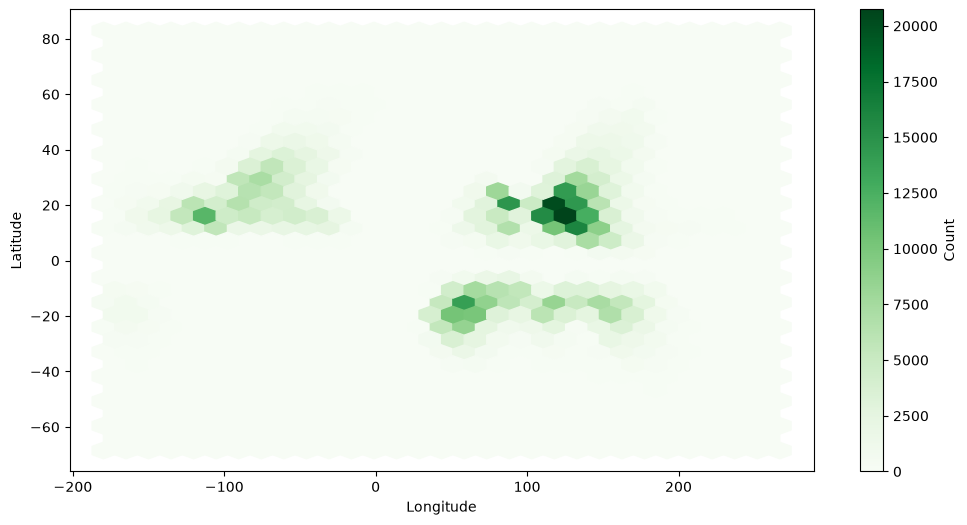

In [30]:
#3.4
plt.figure(figsize=(12, 6))
plt.hexbin(df['LON'],df['LAT'],gridsize=30, cmap='Greens') 
plt.colorbar(label='Count')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

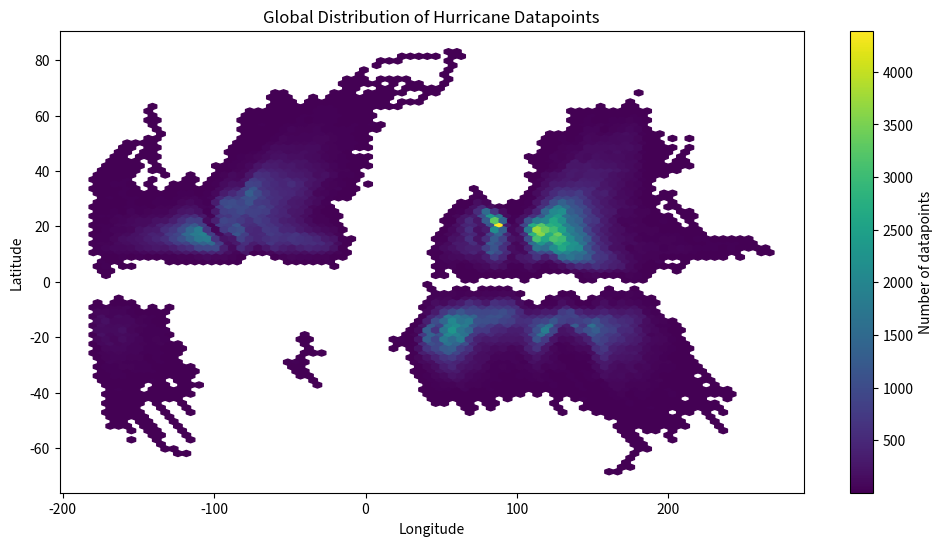

In [18]:
#助教添加
plt.figure(figsize=(12, 6))
plt.hexbin(df["LON"], df["LAT"], gridsize=80, mincnt=1, cmap="viridis")
plt.colorbar(label="Number of datapoints")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Distribution of Hurricane Datapoints")
plt.show()

### 应该用 mincnt=1参数筛选出数量至少为1的格子绘制-1
### --------------------------------------------------------------------------------------------

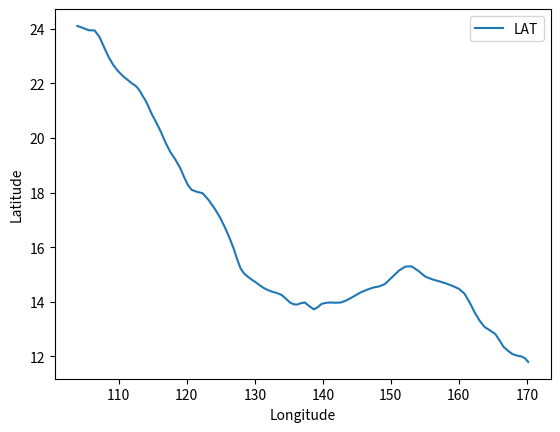

In [19]:
#3.5
df[(df['NAME']=='MANGKHUT')&(df['ISO_TIME'].dt.year==2018)].plot(x='LON', y='LAT')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [20]:
#3.6
data=df[(df['ISO_TIME'].dt.year>=1970) & ((df['BASIN']=='WP') | (df['BASIN']=='EP'))]
data

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,NaN,1006.0,tokyo,main,1088,1088.0,_OO___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,NaN,NaN,NaN,main,1109,1109.0,_PP___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,NaN,1002.0,tokyo,main,1143,1143.0,_OO___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,NaN,NaN,NaN,main,1171,1168.0,_PP___________
350398,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,NaN,998.0,tokyo,main,1182,1179.0,_OO___________
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
707085,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 15:00:00,TS,13.99570,-90.294,NaN,NaN,NaN,PROVISIONAL,0,0.0,P_____________
707086,2022275N10316,2022,76,EP,MM,JULIA,2022-10-10 18:00:00,NR,14.50000,-91.000,NaN,NaN,NaN,PROVISIONAL,0,NaN,O_____________
707174,2022286N15151,2022,80,WP,MM,NaN,2022-10-12 12:00:00,NR,15.20000,151.300,NaN,NaN,NaN,PROVISIONAL,1985,1974.0,O_____________
707175,2022286N15151,2022,80,WP,MM,NaN,2022-10-12 15:00:00,NR,15.05000,151.325,NaN,NaN,NaN,PROVISIONAL,1974,1952.0,P_____________


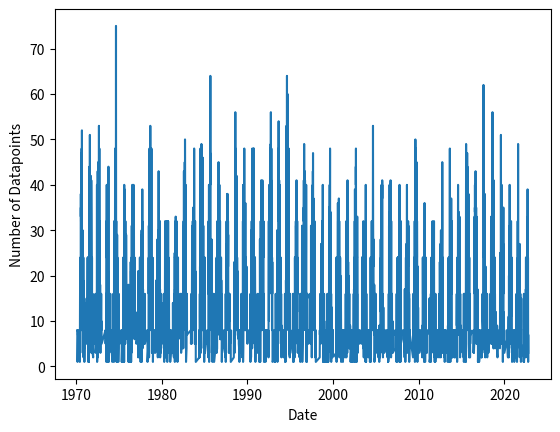

In [21]:
#3.7
%matplotlib inline
data.groupby(data['ISO_TIME'].dt.date).size().plot()
plt.xlabel('Date')
plt.ylabel('Number of Datapoints')
plt.show()

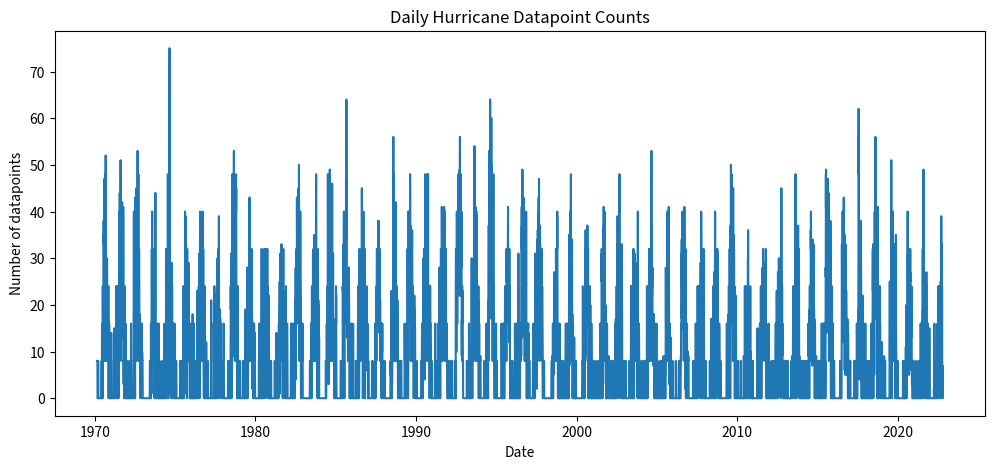

In [36]:
#助教添加 计数、绘图正确，但删除了零计数日-1
daily_counts = (
    data.set_index("ISO_TIME")
    .resample("D")
    .size()
    .rename("count")
)

plt.figure(figsize=(12, 5))
plt.plot(daily_counts.index, daily_counts.values)
plt.xlabel("Date")
plt.ylabel("Number of datapoints")
plt.title("Daily Hurricane Datapoint Counts")
plt.show()

### 代码可以运行但是有观测日期的计数正确但遗漏零计数日期，应该.resample('D').size()建立连续的每日序列，并统计每天的数据点数-1
### --------------------------------------------------------------------------------------------

/tmp/ipykernel_1571487/3411967039.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['day_of_year']=data['ISO_TIME'].dt.dayofyear


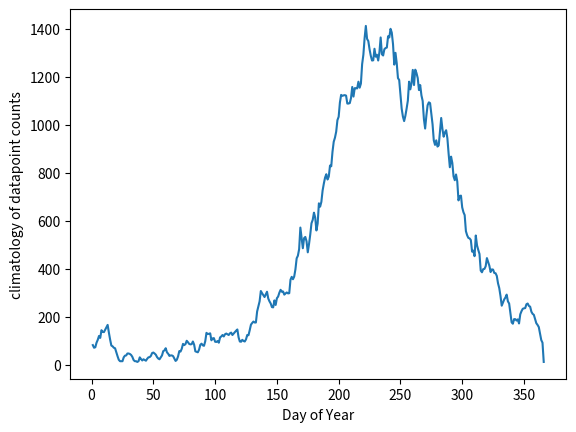

In [34]:
#3.8
data['day_of_year']=data['ISO_TIME'].dt.dayofyear
climatology=data.groupby('day_of_year').size() 
climatology.plot()
plt.xlabel('Day of Year')
plt.ylabel('climatology of datapoint counts')
plt.show()

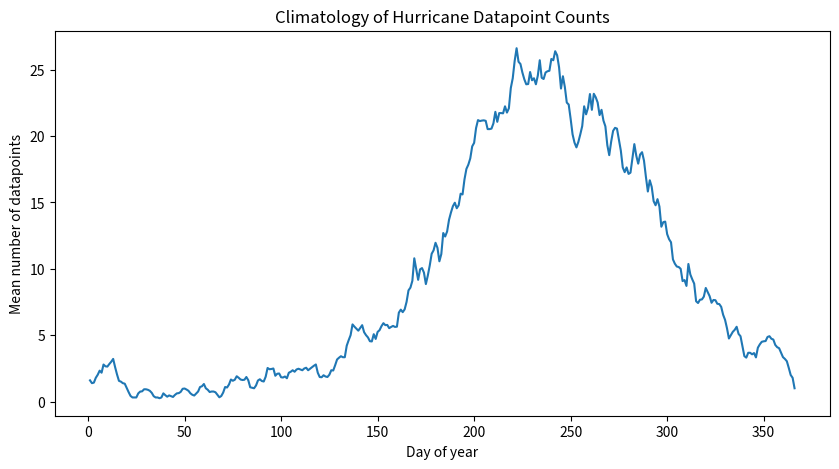

In [37]:
daily = daily_counts.to_frame()
daily["day_of_year"] = daily.index.dayofyear
climatology = daily.groupby("day_of_year")["count"].mean()

plt.figure(figsize=(10, 5))
plt.plot(climatology.index, climatology.values)
plt.xlabel("Day of year")
plt.ylabel("Mean number of datapoints")
plt.title("Climatology of Hurricane Datapoint Counts")
plt.show()

### 代码可以运行但是没有求平均气候态偏大-1
### --------------------------------------------------------------------------------------------

In [31]:
#3.9
#daily_counts = data.groupby(data['ISO_TIME'].dt.date).size()
#助教添加 按日计数，保留零计数日 
daily_counts = data.set_index('ISO_TIME').resample('D').size()
years=data['ISO_TIME'].dt.year.nunique()
climatology_mean=climatology/years
day_of_year=pd.to_datetime(daily_counts.index).dayofyear
anomaly=daily_counts-climatology_mean.loc[day_of_year].values
anomaly.head()

ISO_TIME
1970-02-19    7.018868
1970-02-20    7.094340
1970-02-21    7.188679
1970-02-22    7.377358
1970-02-23    7.490566
Freq: D, dtype: float64

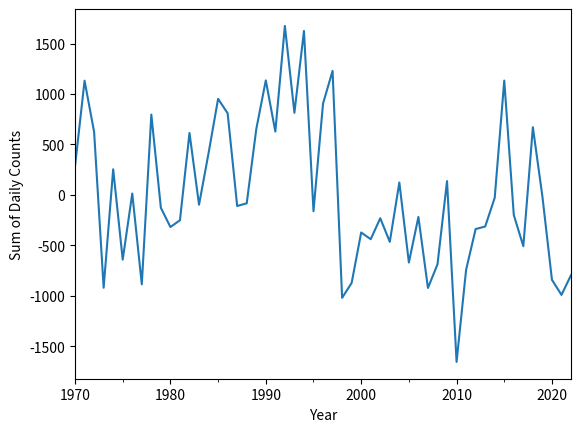

In [32]:
#3.10
anomaly.index = pd.to_datetime(anomaly.index)
SumCounts = anomaly.resample('YE').sum() 
SumCounts.plot()
plt.xlabel('Year')
plt.ylabel('Sum of Daily Counts')
plt.show()

In [33]:
SumCounts.sort_values(ascending=False).head(10)

ISO_TIME
1992    1674.603774
1994    1624.849057
1997    1228.849057
1990    1134.849057
2015    1132.849057
1971    1131.849057
1985     951.849057
1996     904.603774
1993     813.849057
1986     808.849057
dtype: float64

In [35]:
SumCounts.sort_values().head(10)

ISO_TIME
2010   -1655.150943
1998   -1020.150943
2021    -991.150943
2007    -922.150943
1973    -920.150943
1977    -886.150943
1999    -872.150943
2020    -841.396226
2022    -794.981132
2011    -742.150943
dtype: float64

### 代码运行正确但会有一些细节问题，修改代码已经添加仅供参考


### 得分：43/50
### --------------------------------------------------------------------------------------------

In [2]:
#4、Explore a data set

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [3]:
#4.1

welldata=pd.read_excel('WZ1.xlsx')
welldata.head(10)

,序号,站点编号,监测时间,均一化浊度,均一化水位
0,1,WZ1,2023-04-07 15:00:00,1.138439,1.010101
1,2,WZ1,2023-04-07 16:00:00,1.138439,1.010101
2,3,WZ1,2023-04-07 20:00:00,1.094035,1.008931
3,4,WZ1,2023-04-07 21:00:00,1.120315,1.006593
4,5,WZ1,2023-04-07 22:00:00,1.120315,1.006593
5,6,WZ1,2023-04-08 03:00:00,1.062430,1.006593
6,7,WZ1,2023-04-08 04:00:00,1.062430,1.006593
7,8,WZ1,2023-04-08 05:00:00,1.063789,1.005424
8,9,WZ1,2023-04-08 06:00:00,1.063789,1.005424
9,10,WZ1,2023-04-08 07:00:00,1.063789,1.005424


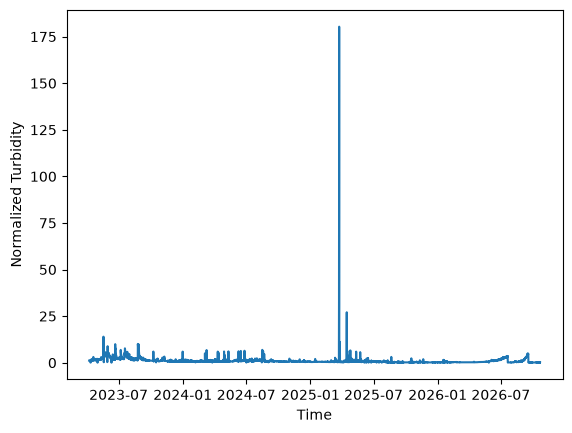

In [4]:
#4.2 选择均一化浊度

plt.plot(welldata['监测时间'], welldata['均一化浊度'])
plt.xlabel('Time')
plt.ylabel('Normalized Turbidity')
plt.show()

In [5]:
#4.3.1基础特征
welldata['均一化浊度'].describe()

count    26675.000000
mean         1.000000
std          3.754472
min          0.014567
25%          0.303527
50%          0.598105
75%          1.008397
max        180.337855
Name: 均一化浊度, dtype: float64

In [7]:
#4.3.2最大值出现的时间
welldata['均一化浊度'].max()
welldata.loc[welldata['均一化浊度'].idxmax(), '监测时间']

Timestamp('2025-03-24 09:00:00')

In [10]:
#4.3.3最小值出现的时间
welldata['均一化浊度'].min()
welldata.loc[welldata['均一化浊度'].idxmin(), '监测时间']

Timestamp('2025-10-15 16:00:00')

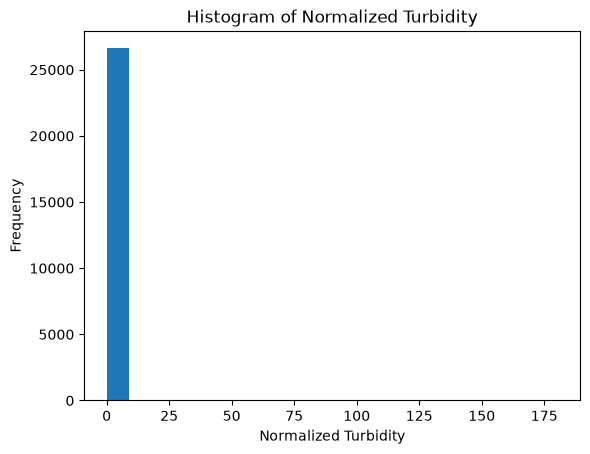

In [23]:
#4.3.4直方图
welldata['均一化浊度'].plot(kind='hist', bins=20)
plt.xlabel('Normalized Turbidity')
plt.title('Histogram of Normalized Turbidity')
plt.show()

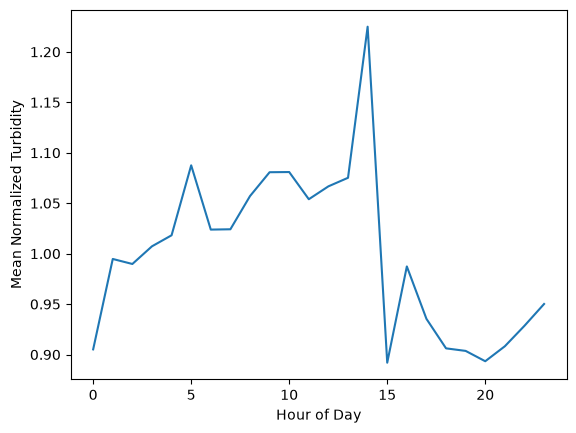

In [22]:
#4.3.5按小时计算平均浊度
welldata['Hour'] = welldata['监测时间'].dt.hour
welldata.groupby('Hour')['均一化浊度'].mean().plot()
plt.xlabel('Hour of Day')
plt.ylabel('Mean Normalized Turbidity')
plt.show()

### 代码结果展示正确且有相应分析但是第一问缺少数据筛选步骤


### 得分：13/15
### --------------------------------------------------------------------------------------------
### 建议后续作业可以在文件夹中放入原始数据方便助教运行并检查代码，并且建议每行代码有相应注释

### 代码有相应解题思路+1